<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkST0151ENSkillsNetwork20531532-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>



# **Final Project: Boston Housing**


##### Estimated time needed: **60** minutes


#### Import the required libraries we need for the lab.


In [16]:
import piplite
await piplite.install(['numpy'],['pandas'])
await piplite.install(['seaborn'])

In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

#### Read the dataset in the csv file from the URL


In [18]:
from js import fetch
import io

URL = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv'
resp = await fetch(URL)
boston_url = io.BytesIO((await resp.arrayBuffer()).to_py())

In [19]:
boston_df=pd.read_csv(boston_url)

#### Add your code below following the instructions given in the course to complete the peer graded assignment


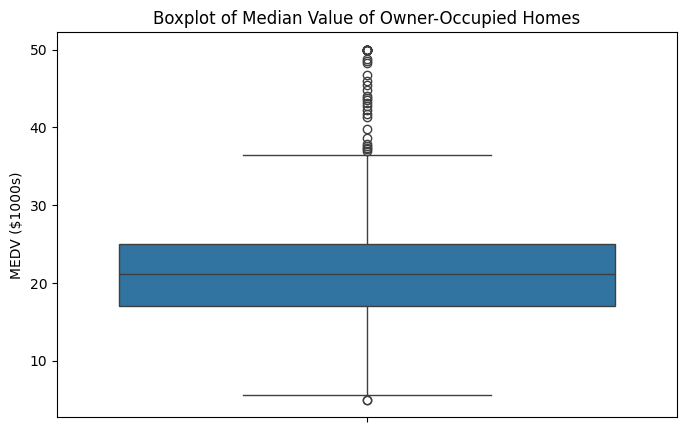

In [20]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=boston_df["MEDV"])
plt.title("Boxplot of Median Value of Owner-Occupied Homes")
plt.ylabel("MEDV ($1000s)")
plt.show()

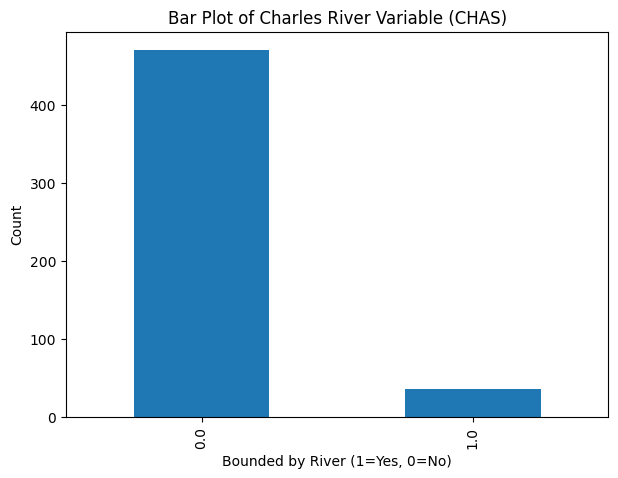

In [21]:
plt.figure(figsize=(7, 5))
boston_df["CHAS"].value_counts().sort_index().plot(kind="bar")
plt.title("Bar Plot of Charles River Variable (CHAS)")
plt.xlabel("Bounded by River (1=Yes, 0=No)")
plt.ylabel("Count")
plt.show()

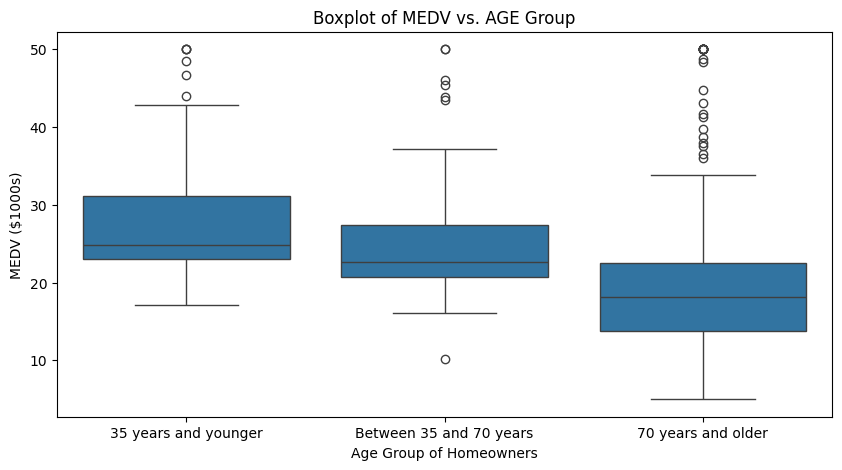

In [22]:
boston_df["AGE_group"] = pd.cut(
    boston_df["AGE"],
    bins=[0, 35, 70, 100],
    labels=["35 years and younger", "Between 35 and 70 years", "70 years and older"],
    include_lowest=True
)

plt.figure(figsize=(10, 5))
sns.boxplot(x="AGE_group", y="MEDV", data=boston_df)
plt.title("Boxplot of MEDV vs. AGE Group")
plt.xlabel("Age Group of Homeowners")
plt.ylabel("MEDV ($1000s)")
plt.show()

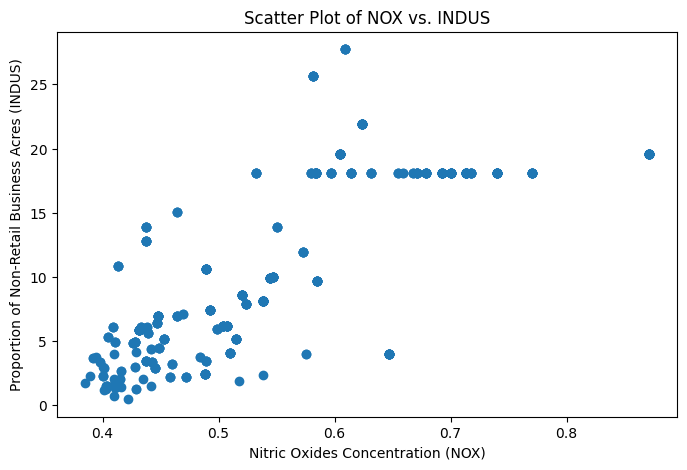

In [23]:
plt.figure(figsize=(8, 5))
plt.scatter(boston_df["NOX"], boston_df["INDUS"])
plt.title("Scatter Plot of NOX vs. INDUS")
plt.xlabel("Nitric Oxides Concentration (NOX)")
plt.ylabel("Proportion of Non-Retail Business Acres (INDUS)")
plt.show()

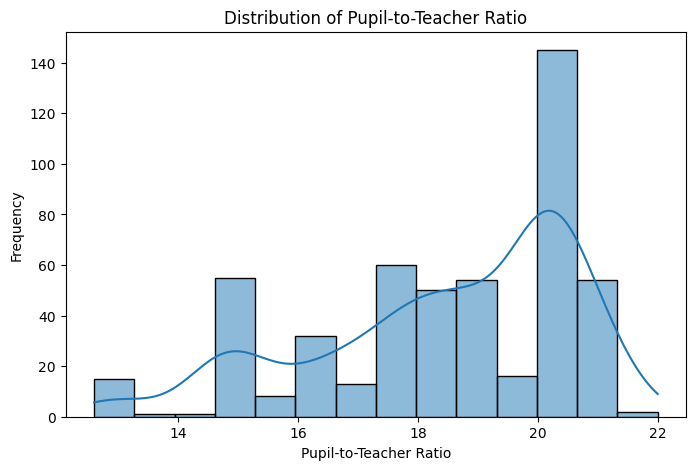

In [24]:
plt.figure(figsize=(8, 5))
sns.histplot(boston_df["PTRATIO"], kde=True)
plt.title("Distribution of Pupil-to-Teacher Ratio")
plt.xlabel("Pupil-to-Teacher Ratio")
plt.ylabel("Frequency")
plt.show()

In [25]:
river = boston_df[boston_df["CHAS"] == 1]["MEDV"]
not_river = boston_df[boston_df["CHAS"] == 0]["MEDV"]

t_stat, p_value = scipy.stats.ttest_ind(
    river, not_river, equal_var=True
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 3.996437466090509
P-value: 7.390623170519905e-05


In [26]:
levene_stat, levene_p = scipy.stats.levene(river, not_river)

print("Levene statistic:", levene_stat)
print("P-value:", levene_p)

Levene statistic: 4.590342218715871
P-value: 0.03263097600633006


In [27]:
group1 = boston_df[boston_df["AGE_group"] == "35 years and younger"]["MEDV"]
group2 = boston_df[boston_df["AGE_group"] == "Between 35 and 70 years"]["MEDV"]
group3 = boston_df[boston_df["AGE_group"] == "70 years and older"]["MEDV"]

f_stat, anova_p = scipy.stats.f_oneway(group1, group2, group3)

print("F-statistic:", f_stat)
print("P-value:", anova_p)

F-statistic: 36.40764999196599
P-value: 1.7105011022702984e-15


In [28]:
corr, corr_p = scipy.stats.pearsonr(
    boston_df["NOX"], boston_df["INDUS"]
)

print("Pearson correlation coefficient:", corr)
print("P-value:", corr_p)

Pearson correlation coefficient: 0.7636514469209192
P-value: 7.913361061210442e-98


In [29]:
model = ols("MEDV ~ DIS", data=boston_df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           1.21e-08
Time:                        16:28:09   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     18.3901      0.817     22.499      0.0